# Assignment Outline 

Please produce in your teams a project proof of concept. All three team members (or two if there are any teams of two) should turn in an identical Colab notebook that they have built together, with all three team members listed as authors. The proof of concept is worth 15% of the overall grade for the project and takes the place of homework for 23-30 October. October.  Please turn in Python notebook file (.ipynb) as well as a PDF.

The proof of concept should contain the following (bolded items are compulsory, unbolded are optional):

**Project title** 

Statement of whether the proof of concept matches the proposal from the same time (yes/no)
    If yes, statements of problem, resources needed, feasibility, and risks/backup plans so that this document can serve as a new proposal

**Discussion of critical challenge** that will be addressed partially or fully in proof of concept document

**Mathematical basis:** Governing equations and derivation; can be recycled from/expanded version of proposal if appropriate.

**Simplifications for proof of concept** - quick discussion of assumptions made to reduce the problem (can you solve a subset of the problem, make simplifying assumptions, use only some data and not all, repeat a paper, etc?)

**Solution to reduced problem** (explanation, code, and at least one plot)

Explanation of major changes compared to proposal (if applicable)

References (if appropriate)

**Statements of contributions of each team member** (1-2 sentences)

There is no fixed length, but more detail than in the proposal is expected. 

**Notes from Dr. Gordon**: Good idea and good proposal in general. More clarity on the basic properties of systems that lead to stiffness (a clear association with very different timescales) would have been good. Eventually, I would be interested to see a solution with and without pyomo. Also worth emphasizing that I will be interested to see the big picture - going into great detail on stiffness of ODEs is interesting, but we are engineers, so if the system could be solved more easily with steady-state approximations we will want to see how that works too.



# Study of Stiff CSTRs in Series

**Yes**, the project proof of concept fits the project listed in our proposal.

## Critical Challenge

### Critical Challenges

The reference ROBER problem [ ] is a single, isothermal reactor whose stiffness is fixed by the rate constants ($k_2/k_1 \approx 7.5\times10^{8}$). Placing the same kinetics in two non-isothermal CSTRs in series changes the nature of the stiffness. The main challenges are listed below.

**1. Temperature-dependent stiffness.**
With Arrhenius rate constants, $k_j(T)$ changes with temperature, so the stiffness ratio varies with operating point and over time. A solver that is efficient in one regime may be inefficient or unstable in another.

**2. Multiple coupled time scales.**
The fast chemistry, the thermal dynamics, and the two residence times ($V_1/F$ and $V_2/F$) all act at once. Flow adds time scales that are absent from the single-reactor ROBER problem, and stiffness is set by the spread among them.

**3. Poor scaling of the state vector.**
In ROBER, $y_2$ is of order $10^{-5}$ while $y_1$ and $y_3$ are of order 1. Adding temperatures in the hundreds of kelvin widens the range further. A single absolute tolerance cannot suit every component, which degrades error control and Newton convergence for both library and hand-coded solvers.

**4. Positivity and conservation.**
A slightly negative $y_2$ can diverge to $-\infty$ and cause overflow, particularly with large explicit steps or loose tolerances. Physical checks include non-negative concentrations and an overall mass balance on A + B + C.

**5. Error propagation between reactors.**
Reactor 2 receives the outlet of reactor 1 as an input, so errors in reactor 1 carry forward. Sequential solving also adds interpolation error from reactor 1's stored solution, which affects the sequential versus simultaneous comparison.

**6. Ignition and multiple steady states.**
For a sufficiently exothermic reaction, the system can show low-conversion and high-conversion steady states and a runaway region. Solver behavior can differ sharply near these points.

**7. Fair comparison of methods.**
A meaningful accuracy and cost comparison requires a trusted reference solution, consistent tolerances across methods, and accounting for startup cost of multistep methods and for Jacobian and Newton cost of implicit methods.

### Exothermicity

The ROBER reference gives isothermal kinetics only. Heats of reaction, activation energies, heat capacities, and cooling parameters can be modeling choices. Treating $\Delta H_j$ as a parameter allows a mild case and a strongly exothermic case to be tested, which shows how solver rankings change with operating regime.

### Proposed Critical Challenge

Stiffness in the two-CSTR system depends on temperature and operating point, so no single method is best everywhere. The challenge is to identify which explicit or implicit method gives the best accuracy per unit of computational cost in each regime, and to determine when explicit methods become unusable.

## Mathematical Basis

### General Governing ODEs (non-isothermal, unequal flows, feeds to both reactors)

**Reactions**

$$A \xrightarrow{k_1} B, \qquad B + B \xrightarrow{k_2} C + B, \qquad B + C \xrightarrow{k_3} A + C$$

**Arrhenius rate constants** (each reaction has its own activation energy, evaluated at the temperature of the reactor it occurs in)

$$k_j(T_n) = k_{0,j}\,\exp\!\left(\frac{-E_j}{R\,T_n}\right), \qquad j = 1,2,3, \quad n = 1,2$$

**Stream heat capacity per volume**

$$\Gamma_s = C_{A,s}\,C_{p,A} + C_{B,s}\,C_{p,B} + C_{C,s}\,C_{p,C}$$

**Cooling duty**

$$Q_n = U_n A_{ex,n}\,(T_n - T_{c,n})$$

---

#### Volume balances

$$\frac{dV_1}{dt} = F_0 - F_1$$

$$\frac{dV_2}{dt} = F_1 + F_3 - F_2$$

#### CSTR 1: species balances

$$\frac{dC_{A1}}{dt} = \frac{F_0}{V_1}\left(C_{A0} - C_{A1}\right) - k_{0,1}e^{-E_1/(RT_1)}C_{A1} + k_{0,3}e^{-E_3/(RT_1)}C_{B1}C_{C1}$$

$$\frac{dC_{B1}}{dt} = \frac{F_0}{V_1}\left(C_{B0} - C_{B1}\right) + k_{0,1}e^{-E_1/(RT_1)}C_{A1} - k_{0,2}e^{-E_2/(RT_1)}C_{B1}^2 - k_{0,3}e^{-E_3/(RT_1)}C_{B1}C_{C1}$$

$$\frac{dC_{C1}}{dt} = \frac{F_0}{V_1}\left(C_{C0} - C_{C1}\right) + k_{0,2}e^{-E_2/(RT_1)}C_{B1}^2$$

#### CSTR 1: energy balance

$$V_1\Gamma_1\frac{dT_1}{dt} = F_0\Gamma_0\,(T_0 - T_1) + V_1\Big[(-\Delta H_1)k_1(T_1)C_{A1} + (-\Delta H_2)k_2(T_1)C_{B1}^2 + (-\Delta H_3)k_3(T_1)C_{B1}C_{C1}\Big] - U_1A_{ex,1}(T_1 - T_{c,1})$$

#### CSTR 2: species balances

$$\frac{dC_{A2}}{dt} = \frac{F_1}{V_2}\left(C_{A1} - C_{A2}\right) + \frac{F_3}{V_2}\left(C_{A03} - C_{A2}\right) - k_{0,1}e^{-E_1/(RT_2)}C_{A2} + k_{0,3}e^{-E_3/(RT_2)}C_{B2}C_{C2}$$

$$\frac{dC_{B2}}{dt} = \frac{F_1}{V_2}\left(C_{B1} - C_{B2}\right) + \frac{F_3}{V_2}\left(C_{B03} - C_{B2}\right) + k_{0,1}e^{-E_1/(RT_2)}C_{A2} - k_{0,2}e^{-E_2/(RT_2)}C_{B2}^2 - k_{0,3}e^{-E_3/(RT_2)}C_{B2}C_{C2}$$

$$\frac{dC_{C2}}{dt} = \frac{F_1}{V_2}\left(C_{C1} - C_{C2}\right) + \frac{F_3}{V_2}\left(C_{C03} - C_{C2}\right) + k_{0,2}e^{-E_2/(RT_2)}C_{B2}^2$$

#### CSTR 2: energy balance

$$V_2\Gamma_2\frac{dT_2}{dt} = F_1\Gamma_1\,(T_1 - T_2) + F_3\Gamma_{03}\,(T_{03} - T_2) + V_2\Big[(-\Delta H_1)k_1(T_2)C_{A2} + (-\Delta H_2)k_2(T_2)C_{B2}^2 + (-\Delta H_3)k_3(T_2)C_{B2}C_{C2}\Big] - U_2A_{ex,2}(T_2 - T_{c,2})$$

---

#### Where the enthalpies enter

The energy balances above come from the general enthalpy form, where $h_i(T)$ is the molar enthalpy of species $i$:

$$V_n\Gamma_n\frac{dT_n}{dt} = \sum_{s\,\in\,\text{inlets}} F_s\sum_i C_{i,s}\Big[h_i(T_s) - h_i(T_n)\Big] + V_n\sum_j(-\Delta H_j)\,r_{j,n} - Q_n$$

For constant heat capacities, $h_i(T_s) - h_i(T_n) = C_{p,i}(T_s - T_n)$, which gives the form used above, with $\Gamma_s(T_s - T_n)$ for each inlet stream. The heat of reaction is $\Delta H_j = \sum_i \nu_{ij}\,h_i$.

---

#### Nomenclature

| Symbol | Meaning | Units |
|---|---|---|
| $A, B, C$ | Chemical species | |
| $n = 1, 2$ | Reactor index | |
| $j = 1, 2, 3$ | Reaction index | |
| $t$ | Time | time |
| $C_{in}$ ($i = A,B,C$) | Concentration of species $i$ in reactor $n$ (also the outlet stream) | mol/vol |
| $C_{i0}$ | Concentration of species $i$ in the feed to CSTR 1 | mol/vol |
| $C_{i03}$ | Concentration of species $i$ in the fresh feed to CSTR 2 | mol/vol |
| $T_n$ | Temperature of reactor $n$ (also its outlet stream) | K |
| $T_0$ | Feed temperature to CSTR 1 | K |
| $T_{03}$ | Fresh feed temperature to CSTR 2 | K |
| $T_{c,n}$ | Coolant temperature for reactor $n$ | K |
| $V_n$ | Liquid volume in reactor $n$ | vol |
| $F_0$ | Volumetric feed flow into CSTR 1 | vol/time |
| $F_1$ | Outlet flow of CSTR 1, which is the inlet from CSTR 1 to CSTR 2 | vol/time |
| $F_2$ | Outlet flow of CSTR 2 | vol/time |
| $F_3$ | Fresh feed flow into CSTR 2 | vol/time |
| $k_{0,j}$ | Pre-exponential factor of reaction $j$ | units of $k_j$ |
| $E_j$ | Activation energy of reaction $j$ | energy/mol |
| $R$ | Gas constant | energy/(mol·K) |
| $k_j(T_n)$ | Arrhenius rate constant of reaction $j$ at temperature $T_n$ | depends on order |
| $\Delta H_j$ | Heat of reaction $j$ (negative if exothermic) | energy/mol |
| $C_{p,i}$ | Molar heat capacity of species $i$ | energy/(mol·K) |
| $\Gamma_s$ | Heat capacity per volume of stream or reactor contents $s$ | energy/(vol·K) |
| $h_i(T)$ | Molar enthalpy of species $i$ at temperature $T$ | energy/mol |
| $U_n$ | Overall heat transfer coefficient for reactor $n$ | energy/(time·area·K) |
| $A_{ex,n}$ | Heat exchange area of reactor $n$ | area |
| $Q_n$ | Rate of heat removal by cooling from reactor $n$ | energy/time |

---

**State vector (10 ODEs):**

$$\mathbf{y} = [V_1,\, C_{A1},\, C_{B1},\, C_{C1},\, T_1,\, V_2,\, C_{A2},\, C_{B2},\, C_{C2},\, T_2]$$

## Simplifications for Proof of Concept

To simplify this problem for the proof of concept, we'll assume that this is an isothermal process, as is given by the base version of the Robertson problem (the reaction we chose, used for evaluating solvers of stiff problems). We'll solve with multiple different solvers, some of which might fail due to the behavior of the specific algorithms. This will serve as proof of concept, and in the final version of the project we'll expand to using pyomo, solving analytically, and analyzing each of the algorithms mathematically. 

## Solution to Reduced Problem

### Governing ODEs (isothermal, constant volume)

Reactions: $A \xrightarrow{k_1} B$, $\quad B + B \xrightarrow{k_2} C + B$, $\quad B + C \xrightarrow{k_3} A + C$

Only A is fed to CSTR 1, with feed concentration $C_{A0}$. CSTR 2 is fed by the outlet of CSTR 1. Here $F$ is the volumetric flow rate, $V_1$ and $V_2$ are the reactor volumes, and $C_{A1}, C_{B1}, C_{C1}$ and $C_{A2}, C_{B2}, C_{C2}$ are the concentrations in reactors 1 and 2.

**CSTR 1**

$$\frac{dC_{A1}}{dt} = \frac{F}{V_1}\left(C_{A0} - C_{A1}\right) - k_1 C_{A1} + k_3 C_{B1} C_{C1}$$

$$\frac{dC_{B1}}{dt} = -\frac{F}{V_1} C_{B1} + k_1 C_{A1} - k_2 C_{B1}^2 - k_3 C_{B1} C_{C1}$$

$$\frac{dC_{C1}}{dt} = -\frac{F}{V_1} C_{C1} + k_2 C_{B1}^2$$

**CSTR 2**

$$\frac{dC_{A2}}{dt} = \frac{F}{V_2}\left(C_{A1} - C_{A2}\right) - k_1 C_{A2} + k_3 C_{B2} C_{C2}$$

$$\frac{dC_{B2}}{dt} = \frac{F}{V_2}\left(C_{B1} - C_{B2}\right) + k_1 C_{A2} - k_2 C_{B2}^2 - k_3 C_{B2} C_{C2}$$

$$\frac{dC_{C2}}{dt} = \frac{F}{V_2}\left(C_{C1} - C_{C2}\right) + k_2 C_{B2}^2$$

**State vector:** $\mathbf{y} = [C_{A1},\, C_{B1},\, C_{C1},\, C_{A2},\, C_{B2},\, C_{C2}]$

The coupling between reactors is one-way. Reactor 2 depends on reactor 1 through the inlet terms $C_{A1}, C_{B1}, C_{C1}$, and reactor 1 does not depend on reactor 2. Within each reactor, the three species are coupled through the reaction terms.

In [2]:
from scipy.integrate import solve_ivp

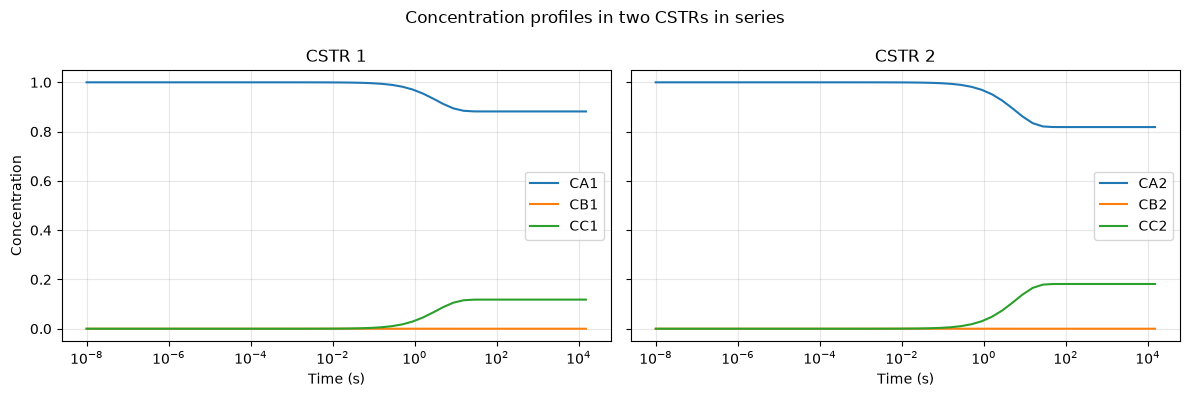

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Robertson-style kinetic parameters from above
k1 = 0.04       # 1/s
k2 = 3e7         # rate constant for B + B -> C + B
k3 = 1e4         # rate constant for B + C -> A + C

# Example operating conditions (edit these to match the system being modeled)
F = 1.0          # volumetric flow rate
V1 = 10.0        # reactor 1 volume
V2 = 10.0        # reactor 2 volume
CA0 = 1.0        # A concentration in the CSTR 1 feed

# Both reactors initially contain the feed composition; CSTR 2 receives CSTR 1's outlet.
Y0 = np.array([1.0, 0.0, 0.0])  # [CA, CB, CC]
y0_1 = Y0.copy()
y0_2 = Y0.copy()


def cstr1_odes(t, y, F, V1, CA0, k1, k2, k3):
    """Concentration balances for CSTR 1, with fresh A-only feed."""
    CA, CB, CC = y
    dilution = F / V1
    return [
        dilution * (CA0 - CA) - k1 * CA + k3 * CB * CC,
        -dilution * CB + k1 * CA - k2 * CB**2 - k3 * CB * CC,
        -dilution * CC + k2 * CB**2,
    ]


def cstr2_odes(t, y, F, V2, k1, k2, k3, cstr1_solution):
    """Concentration balances for CSTR 2, using CSTR 1's outlet as its feed."""
    CA, CB, CC = y
    CA1, CB1, CC1 = cstr1_solution.sol(t)
    dilution = F / V2
    return [
        dilution * (CA1 - CA) - k1 * CA + k3 * CB * CC,
        dilution * (CB1 - CB) + k1 * CA - k2 * CB**2 - k3 * CB * CC,
        dilution * (CC1 - CC) + k2 * CB**2,
    ]


# Log-spaced output resolves the fast transient as well as the slower evolution.
t_start, t_end = 0.0, 15000.0
t_eval = np.geomspace(1e-8, t_end)

solver_options = {
    "method": "Radau", 
    "t_eval": t_eval,
    "rtol": 1e-8,
    "atol": 1e-10,
    "dense_output": True,
}

solution_1 = solve_ivp(cstr1_odes, (t_start, t_end), y0_1, args=(F, V1, CA0, k1, k2, k3), **solver_options)
solution_2 = solve_ivp(cstr2_odes, (t_start, t_end), y0_2, args=(F, V2, k1, k2, k3, solution_1), **solver_options)

species = ["A", "B", "C"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i, label in enumerate(species):
    axes[0].plot(solution_1.t, solution_1.y[i], label=f"C{label}1")
    axes[1].plot(solution_2.t, solution_2.y[i], label=f"C{label}2")

for ax, title in zip(axes, ["CSTR 1", "CSTR 2"]):
    ax.set_xscale("log")
    ax.set_xlabel("Time (s)")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Concentration")
fig.suptitle("Concentration profiles in two CSTRs in series")
fig.tight_layout()
plt.show()

It worked when using the Radau solver, which works for stiff problems. We can also see for an arbitrary inlet composition and reactor volumes, it reaches a new steady state. Now lets test the idea by attempting the problem with a different solver, RK45 in this case. 

In [16]:
solver_options = {
    "method": "RK45", 
    "t_eval": t_eval,
    "rtol": 1e-8,
    "atol": 1e-10,
    "dense_output": True,
}

solution_1 = solve_ivp(cstr1_odes, (t_start, t_end), y0_1, args=(F, V1, CA0, k1, k2, k3), **solver_options)
solution_2 = solve_ivp(cstr2_odes, (t_start, t_end), y0_2, args=(F, V2, k1, k2, k3, solution_1), **solver_options)

species = ["A", "B", "C"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i, label in enumerate(species):
    axes[0].plot(solution_1.t, solution_1.y[i], label=f"C{label}1")
    axes[1].plot(solution_2.t, solution_2.y[i], label=f"C{label}2")

for ax, title in zip(axes, ["CSTR 1", "CSTR 2"]):
    ax.set_xscale("log")
    ax.set_xlabel("Time (s)")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Concentration")
fig.suptitle("Concentration profiles in two CSTRs in series")
fig.tight_layout()
plt.show()

KeyboardInterrupt: 

This failed to converge after 725m, as RK45 doesn't do as well will stiff problems. In the final project submission, we'll dive into the accuracy and convergence of each of these solvers in this stiff system, as well as introduce an exothermic reaction.

## Statement of Contributions

We both worked together to find an example reaction/problem to solve from literature. Charles gave the solution to the reduced problem, and simplifications for proof of concept. Nick delivered the mathematical basis and the analytical solution to the reduced problem. We worked on critical challenges.